# Import and Install liberaries

In [ ]:
import argparse
import os
import random
import torch
import torch.nn as nn
import torch.nn.parallel
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as dset
import torchvision.transforms as transforms
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import torch.nn.functional as F
from torch.optim import Adam
from torch.optim.lr_scheduler import StepLR
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor
from tqdm import tqdm
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from IPython.display import clear_output
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader, random_split, ConcatDataset

In [ ]:
manualSeed = 2000
print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)

torch.use_deterministic_algorithms(False)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

Random Seed:  2000


# Helpers

In [ ]:
def live_plot_gan(data_dict, figsize=(18, 5), title="GAN Training Progress"):
    from IPython.display import clear_output
    import matplotlib.pyplot as plt

    clear_output(wait=True)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=figsize)

    ax1.set_title("Losses")
    ax1.set_xlabel("Epochs")
    ax1.grid(True)
    lines = []
    labels = []

    if "D Loss" in data_dict:
        l_d, = ax1.plot(data_dict["D Loss"], "r-", label="Discriminator Loss", marker='o')
        ax1.set_ylabel("Discriminator Loss", color=l_d.get_color())
        ax1.tick_params(axis='y', labelcolor=l_d.get_color())
        lines.append(l_d)
        labels.append("Discriminator Loss")

    if "G Loss" in data_dict:
        if "D Loss" in data_dict:
            ax1_right = ax1.twinx()
            l_g, = ax1_right.plot(data_dict["G Loss"], "b-", label="Generator Loss", marker='o')
            ax1_right.set_ylabel("Generator Loss", color=l_g.get_color())
            ax1_right.tick_params(axis='y', labelcolor=l_g.get_color())
            lines.append(l_g)
            labels.append("Generator Loss")
        else:
            l_g, = ax1.plot(data_dict["G Loss"], "b-", label="Generator Loss", marker='o')
            ax1.set_ylabel("Generator Loss", color=l_g.get_color())
            ax1.tick_params(axis='y', labelcolor=l_g.get_color())
            lines.append(l_g)
            labels.append("Generator Loss")

    ax1.legend(lines, labels, loc='upper right')

    ax2.set_title("Discriminator Output")
    ax2.set_xlabel("Epochs")
    ax2.grid(True)
    lines = []
    labels = []

    if "D(x)" in data_dict:
        l_dx, = ax2.plot(data_dict["D(x)"], "r--", label="D(x)", marker='x', alpha=0.7)
        ax2.set_ylabel("D(x)", color=l_dx.get_color())
        ax2.tick_params(axis='y', labelcolor=l_dx.get_color())
        lines.append(l_dx)
        labels.append("D(x)")

    if "D(G(z))" in data_dict:
        if "D(x)" in data_dict:
            ax2_right = ax2.twinx()
            l_dgz, = ax2_right.plot(data_dict["D(G(z))"], "g-", label="D(G(z))", marker='^')
            ax2_right.set_ylabel("D(G(z))", color=l_dgz.get_color())
            ax2_right.tick_params(axis='y', labelcolor=l_dgz.get_color())
            lines.append(l_dgz)
            labels.append("D(G(z))")
        else:
            l_dgz, = ax2.plot(data_dict["D(G(z))"], "g-", label="D(G(z))", marker='^')
            ax2.set_ylabel("D(G(z))", color=l_dgz.get_color())
            ax2.tick_params(axis='y', labelcolor=l_dgz.get_color())
            lines.append(l_dgz)
            labels.append("D(G(z))")

    ax2.legend(lines, labels, loc='upper right')

    ax3.set_title("Parameter Update Ratios")
    ax3.set_xlabel("Epochs")
    ax3.grid(True)

    if "Update Gen" in data_dict:
        l1, = ax3.plot(data_dict["Update Gen"], "b-", label="Generator Update Ratio", marker='o')
        ax3.set_ylabel("Generator Update Ratio", color=l1.get_color())
        ax3.tick_params(axis='y', labelcolor=l1.get_color())

    ax3_right = ax3.twinx()
    if "Update Disc" in data_dict:
        l2, = ax3_right.plot(data_dict["Update Disc"], "r-", label="Discriminator Update Ratio", marker='^')
        ax3_right.set_ylabel("Discriminator Update Ratio", color=l2.get_color())
        ax3_right.tick_params(axis='y', labelcolor=l2.get_color())

    ax3.axhline(y=0.001, color='gray', linestyle='--', label='Target Ratio (10^-3)')

    lines, labels = ax3.get_legend_handles_labels()
    lines2, labels2 = ax3_right.get_legend_handles_labels()
    ax3.legend(lines + lines2, labels + labels2, loc='upper right')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def plot_generated_images(img_grid, figsize=(8,8)):
    plt.figure(figsize=figsize)
    plt.axis("off")
    plt.title(f"Generated Images")

    plt.imshow(np.transpose(img_grid, (1, 2, 0)))
    plt.show()

def compute_update_ratio(net, optimizer):
    total_update_norm = 0.0
    total_param_norm = 0.0
    # Loop over parameter groups and parameters
    for group in optimizer.param_groups:
        lr = group.get('lr', 0.001)  # default to 0.001 if not found
        for p in net.parameters():
            if p.grad is not None:
                param_norm = p.data.norm(2)
                # Compute update magnitude using the learning rate times the gradient
                update = lr * p.grad.data
                update_norm = update.norm(2)
                total_update_norm += update_norm.item()
                total_param_norm += param_norm.item()
    # Return ratio if possible
    return total_update_norm / total_param_norm if total_param_norm > 0 else 0.0

def trainer(model, data_loader, criterion, optimizer, device, n_step):
    train_loss = 0.0
    correct = 0
    total = 0
    update_ratios = []
    model.train()
    for i, (x, y) in enumerate(data_loader):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()

        for param in model.parameters():
            if param.grad is not None:
                param_norm = param.norm()
                grad_norm = param.grad.norm()
                if param_norm != 0 and grad_norm != 0:
                    update_ratio = (optimizer.param_groups[0]['lr'] * grad_norm / param_norm).item()
                    update_ratios.append(update_ratio)

        optimizer.step()
        train_loss += loss.item() * y.size(0)
        _, predicted = torch.max(logits, 1)
        correct += (predicted == y).sum().item()
        total += y.size(0)

        if i >= n_step:
            break

    avg_loss = train_loss / total
    accuracy = 100 * correct / total
    avg_update_ratio = sum(update_ratios) / len(update_ratios) if update_ratios else 0
    return avg_loss, accuracy, avg_update_ratio


def validator(model, data_loader, criterion, device, n_step):
    valid_loss = 0.0
    correct = 0
    total = 0
    model.eval()
    with torch.no_grad():
        for i, (x, y) in enumerate(data_loader):
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            valid_loss += loss.item() * y.size(0)
            _, predicted = torch.max(logits, 1)
            correct += (predicted == y).sum().item()
            total += y.size(0)

            if i >= n_step:
                break

    avg_loss = valid_loss / total
    accuracy = 100 * correct / total
    return avg_loss, accuracy

def test_model(model, test_loader, criterion, n_class, device):
    model.eval()
    test_loss = 0.0
    class_correct = list(0.0 for i in range(n_class))
    class_total = list(0.0 for i in range(n_class))

    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            test_loss += loss.item() * x.size(0)
            _, pred = torch.max(logits, 1)
            correct = pred.eq(y).float()

            for i in range(y.size(0)):
                label = y[i]
                class_correct[label] += correct[i].item()
                class_total[label] += 1

    # Finalize the average test loss
    test_loss /= len(test_loader.dataset)
    print(f"Test Loss: {test_loss:.6f}\n")

    # Output the accuracy for each class
    for i in range(n_class):
        if class_total[i] > 0:
            print(f'Accuracy of class {i}: {100 * class_correct[i] / class_total[i]:.2f}% ({int(class_correct[i])}/{int(class_total[i])})')
        else:
            print(f'Accuracy of class {i}: N/A (no samples in test set)')

    # Calculate and print overall accuracy
    overall_accuracy = 100. * sum(class_correct) / sum(class_total)
    print(f'\nOverall Test Accuracy: {overall_accuracy:.2f}% ({int(sum(class_correct))}/{int(sum(class_total))})')

def save_checkpoints(model, optimizer, path):
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
    }, path)

    print(f"Model and optimizer checkpoints saved at {path}")

def load_checkpoints(model, optimizer, path):
    checkpoint = torch.load(path)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    print(f"Model and optimizer checkpoints loaded from {path}")
    return model, optimizer

# Load MNIST Dataset

In [ ]:
# Parameters
b_size = 64
im_size = 32
c_dim = 1

# Data transformations
transform = transforms.Compose([
    transforms.Resize(im_size),
    transforms.CenterCrop(im_size),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

# Load the full MNIST dataset
train_set = MNIST(
    root="datasets", train=True, download=True, transform=transform
)
test_set = MNIST(
    root="datasets", train=False, download=True, transform=transform
)

# Load both MNIST train and test sets
train_set = MNIST(root="datasets", train=True, download=True, transform=transform)
test_set = MNIST(root="datasets", train=False, download=True, transform=transform)

# Merge train and test sets into one dataset
full_dataset = ConcatDataset([train_set, test_set])

# DataLoader (Single Dataset)
data_loader = DataLoader(full_dataset, shuffle=True, batch_size=b_size)

# Test DataLoader
for x, _ in data_loader:
    print(x.shape)
    break

torch.Size([64, 1, 32, 32])


# GAN (Generator + Discriminator)

In [ ]:
# this version is a bit complecated and big so it takes hours and hours and does not converge
# easly ( i think because i used many laysers ? and )
class Generator(nn.Module):
    def __init__(self, z_dim, n_fm):
        super(Generator, self).__init__()
        self.gen = nn.Sequential(
            nn.ConvTranspose2d( z_dim, n_fm * 4, 4, 1, 0, bias=False),
            nn.BatchNorm2d(n_fm * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d( n_fm * 4, n_fm * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(n_fm * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d( n_fm * 2, n_fm, 4, 2, 1, bias=False),
            nn.BatchNorm2d(n_fm),
            nn.ReLU(True),

            nn.ConvTranspose2d( n_fm, c_dim, 4, 2, 1, bias=False),
            nn.Tanh()
          )

        self.apply(self.weights_init)

    def weights_init(self, m):
        classname = m.__class__.__name__
        if classname.find('Conv') != -1:
            nn.init.normal_(m.weight.data, 0.0, 0.02)
        elif classname.find('BatchNorm') != -1:
            nn.init.normal_(m.weight.data, 1.0, 0.02)
            nn.init.constant_(m.bias.data, 0)

    def forward(self, x):
        return self.gen(x)

# test generator
z_dim = 100
n_fm = 64
netG = Generator(z_dim, n_fm)
x = torch.randn(b_size, z_dim, 1, 1)

netG(x).shape

torch.Size([64, 1, 32, 32])

In [ ]:
class Discriminator(nn.Module):
    def __init__(self, z_dim, n_fm):
        super(Discriminator, self).__init__()
        self.disc = nn.Sequential(
            nn.Conv2d(c_dim, n_fm, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(n_fm, n_fm * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(n_fm * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(n_fm * 2, n_fm * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(n_fm * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(n_fm * 4, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

        self.apply(self.weights_init)

    def weights_init(self, m):
        classname = m.__class__.__name__
        if classname.find('Conv') != -1:
            nn.init.normal_(m.weight.data, 0.0, 0.02)
        elif classname.find('BatchNorm') != -1:
            nn.init.normal_(m.weight.data, 1.0, 0.02)
            nn.init.constant_(m.bias.data, 0)

    def forward(self, x):
        return self.disc(x)



# test discriminator
netD = Discriminator(z_dim, n_fm)
x = torch.randn(b_size, c_dim, im_size, im_size)

netD(x).shape

torch.Size([64, 1, 1, 1])

# Training

In [ ]:
# Hyperparameters
n_epochs = 100
lr = 0.0002
beta1, beta2 = 0.5, 0.999
z_dim = 100
b_size = b_size
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# Init objects
criterion = nn.BCELoss()

# fixed noise ==> used for evaluation
fixed_noise = torch.randn(64, z_dim, 1, 1, device=device)

# Establish convention for real and fake labels during training
r_lbl = 1.0
f_lbl = 0.0

# optimizers
optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, beta2))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, beta2))

# init GAN
netG = Generator(z_dim, n_fm).to(device)
netD = Discriminator(z_dim, n_fm).to(device)

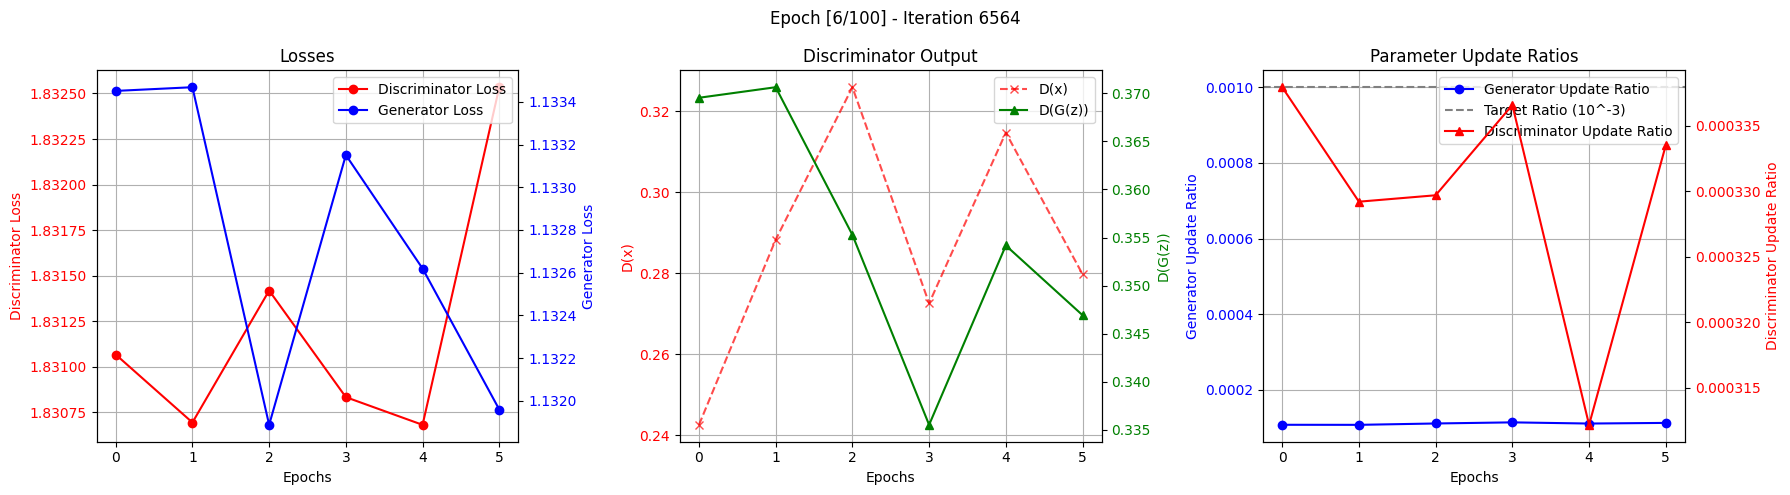

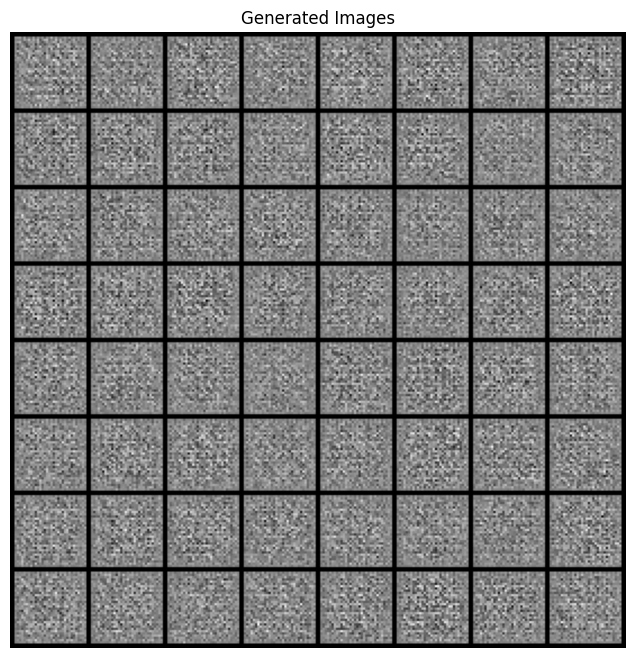

In [ ]:
# metrics
history = {
    "D Loss": [],
    "G Loss": [],
    "D(x)": [],
    "D(G(z))": [],
    "Update Gen": [],
    "Update Disc": []
}
img_list = []

iters = 0
for epoch in range(n_epochs):
    d_epoch_loss, g_epoch_loss = 0.0, 0.0

    for i, (r_imgs, _) in enumerate(data_loader):

        # Data preparation
        b_size = r_imgs.size(0)
        r_imgs = r_imgs.to(device)
        noise = torch.randn(b_size, z_dim, 1, 1, device=device)

        f_imgs = netG(noise)

        r_lbls = torch.full((b_size,), r_lbl, device=device)
        f_lbls = torch.full((b_size,), f_lbl, device=device)

        # -----------------------
        # Train Discriminator
        # -----------------------
        netD.zero_grad()
        r_out = netD(r_imgs).view(-1)
        d_r_loss = criterion(r_out, r_lbls)

        f_out = netD(f_imgs.detach()).view(-1)
        d_f_loss = criterion(f_out, f_lbls)

        d_loss = d_r_loss + d_f_loss
        d_loss.backward()
        optimizerD.step()

        # -----------------------
        # Train Generator
        # -----------------------
        netG.zero_grad()
        g_out = netD(f_imgs).view(-1)
        g_loss = criterion(g_out, r_lbls)
        g_loss.backward()
        optimizerG.step()

        # Track batch losses
        d_epoch_loss += d_loss.item()
        g_epoch_loss += g_loss.item()

        iters += 1

    # Calculate and store epoch-level metrics
    history["D Loss"].append(d_epoch_loss / len(data_loader))
    history["G Loss"].append(g_epoch_loss / len(data_loader))
    history["D(x)"].append(r_out.mean().item())
    history["D(G(z))"].append(g_out.mean().item())

    # Compute update ratios for generator and discriminator
    update_gen_ratio = compute_update_ratio(netG, optimizerG)
    update_disc_ratio = compute_update_ratio(netD, optimizerD)
    history["Update Gen"].append(update_gen_ratio)
    history["Update Disc"].append(update_disc_ratio)

    # Update live plot at the end of the epoch (first call)
    live_plot_gan({
        "D Loss": history["D Loss"],
        "G Loss": history["G Loss"],
        "D(G(z))": history["D(G(z))"],
        "Update Gen": history["Update Gen"],
        "Update Disc": history["Update Disc"]
    }, title=f"GAN Training Progress Epoch [{epoch+1}/{n_epochs}]")

    # Save generated images and update live plots periodically
    with torch.no_grad():
        fake = netG(fixed_noise).cpu()
        img_grid = vutils.make_grid(fake, padding=2, normalize=True)
        img_list.append(img_grid)

        # Update live metrics using the helper (now including update ratios)
        live_plot_gan({
            "D Loss": history["D Loss"],
            "G Loss": history["G Loss"],
            "D(G(z))": history["D(G(z))"],
            "D(x)": history["D(x)"],
            "Update Gen": history["Update Gen"],
            "Update Disc": history["Update Disc"]
        }, title=f"Epoch [{epoch+1}/{n_epochs}] - Iteration {iters}")

        # Plot generated images using the helper
        plot_generated_images(img_grid)